In [1]:
# Basic libraries
import pandas as pd
import numpy as np

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns
import pydot

#Evaluation libraries
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV

#DL libraries
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation, Dropout
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical


In [2]:
train = pd.read_csv("/fashion-mnist_train.csv")
test = pd.read_csv("/fashion-mnist_test.csv")

In [5]:
train

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59995,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
59996,1,0,0,0,0,0,0,0,0,0,...,73,0,0,0,0,0,0,0,0,0
59997,8,0,0,0,0,0,0,0,0,0,...,160,162,163,135,94,0,0,0,0,0
59998,8,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [3]:
train.shape

(60000, 785)

In [4]:
test.shape

(10000, 785)

In [20]:
x_train = train.drop('label', axis = 1)
x_test = test.drop('label', axis = 1)
y_train = train['label']
y_test = test['label']

In [7]:
x_train.shape

(60000, 784)

In [8]:
y_train.shape

(60000,)

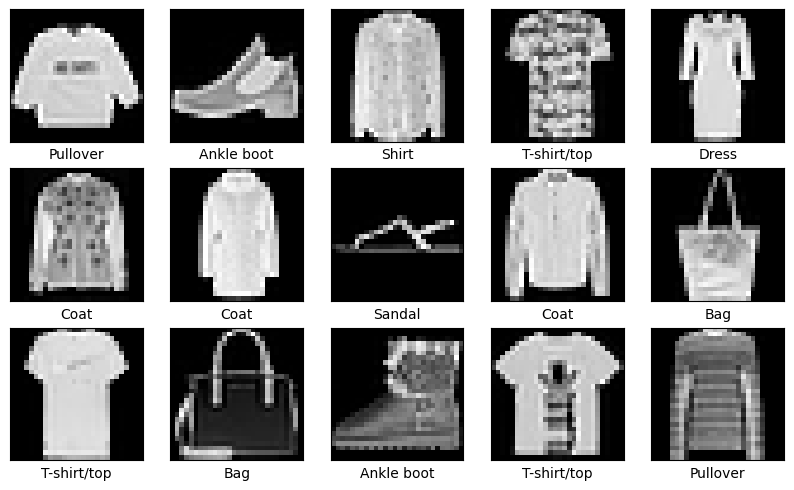

In [11]:
#Reshaping the dataset
x_train_reshape = x_train.values.reshape(-1,28,28)
x_test_reshape = x_test.values.reshape(-1,28,28)

#Names of clothing accessories in order
col_names = ['T-shirt/top','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Ankle boot']

#Visualizing the images
plt.figure(figsize=(10,10))
for i in range(15):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(x_train_reshape[i], cmap='gray')
    plt.xlabel(col_names[y_train[i]])
plt.show()

In [13]:
y_train_fashion = to_categorical(y_train, num_classes=10)

y_test_fashion = to_categorical(y_test, num_classes=10)

In [30]:
#Creating base for neural network
# Improved MLP (Dense) Architecture
model = keras.Sequential([
    keras.Input(shape=(784,)),
    layers.Dense(512, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.25),

    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.25),

    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),

    layers.Dense(10, activation='softmax')
])
#compiling the model
model.compile(loss='categorical_crossentropy',
              optimizer='adam',
              metrics = ['accuracy'])

In [31]:
#fitting the model
history= model.fit(x_train,y_train_fashion,batch_size=128,epochs=30,validation_data=(x_test,y_test_fashion))

Epoch 1/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 16s 24ms/step - accuracy: 0.8169 - loss: 0.5108 - val_accuracy: 0.8510 - val_loss: 0.4014
Epoch 2/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - accuracy: 0.8533 - loss: 0.4000 - val_accuracy: 0.8476 - val_loss: 0.4055
Epoch 3/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 11s 24ms/step - accuracy: 0.8638 - loss: 0.3724 - val_accuracy: 0.8688 - val_loss: 0.3610
Epoch 4/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 11s 23ms/step - accuracy: 0.8715 - loss: 0.3525 - val_accuracy: 0.8624 - val_loss: 0.3730
Epoch 5/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 11s 23ms/step - accuracy: 0.8749 - loss: 0.3420 - val_accuracy: 0.8638 - val_loss: 0.3719
Epoch 6/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 19s 20ms/step - accuracy: 0.8778 - loss: 0.3331 - val_accuracy: 0.8841 - val_loss: 0.3200
Epoch 7/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 11s 23ms/step - accuracy: 0.8812 - loss: 0.3205 - val_accuracy: 0.8872 - val_loss: 0.3184
Epoch 8/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 11s 23ms/step - accuracy: 0.8842 - loss: 0.3117 - 

In [33]:
test_loss_fashion, test_acc_fashion = model.evaluate(x_test, y_test_fashion)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8987 - loss: 0.3123


In [35]:
#Predicting the labels-Fashion
y_predict_fash = model.predict(x_test)
y_predict_fash=np.argmax(y_predict_fash, axis=1)
y_test_fash_eval=np.argmax(y_test_fashion, axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step


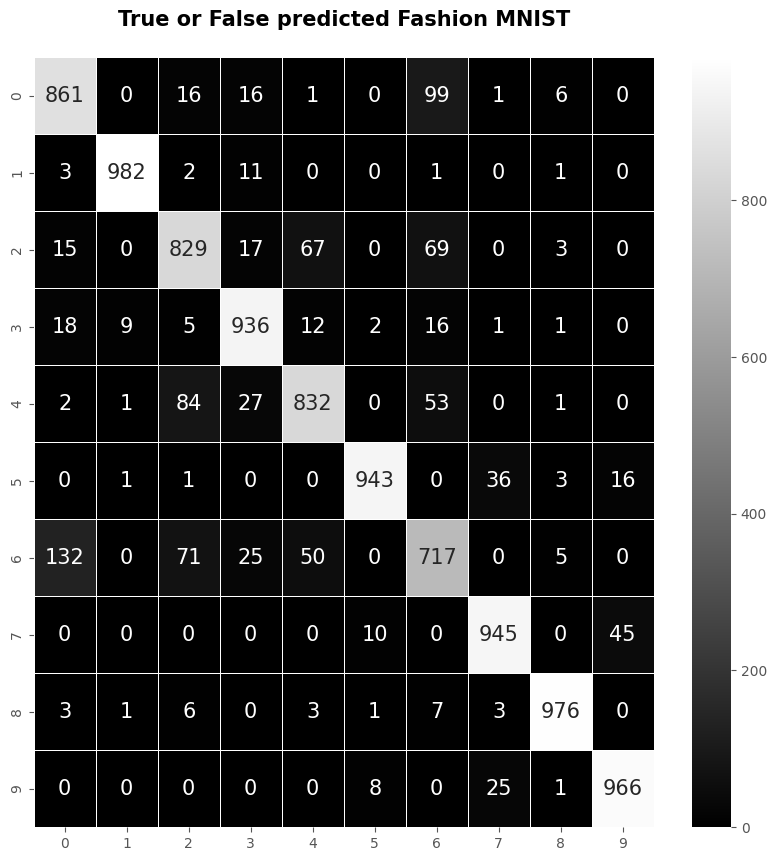

In [37]:
con_mat=confusion_matrix(y_test_fash_eval,y_predict_fash)
plt.style.use('ggplot')
plt.figure(figsize=(10,10))
sns.heatmap(con_mat,annot=True,annot_kws={'size': 15},linewidths=0.5,fmt="d",cmap="gray")
plt.title('True or False predicted Fashion MNIST\n',fontweight='bold',fontsize=15)
plt.show()

In [38]:
from sklearn.metrics import classification_report

print(classification_report(y_test_fash_eval,y_predict_fash))

              precision    recall  f1-score   support

           0       0.83      0.86      0.85      1000
           1       0.99      0.98      0.98      1000
           2       0.82      0.83      0.82      1000
           3       0.91      0.94      0.92      1000
           4       0.86      0.83      0.85      1000
           5       0.98      0.94      0.96      1000
           6       0.75      0.72      0.73      1000
           7       0.93      0.94      0.94      1000
           8       0.98      0.98      0.98      1000
           9       0.94      0.97      0.95      1000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



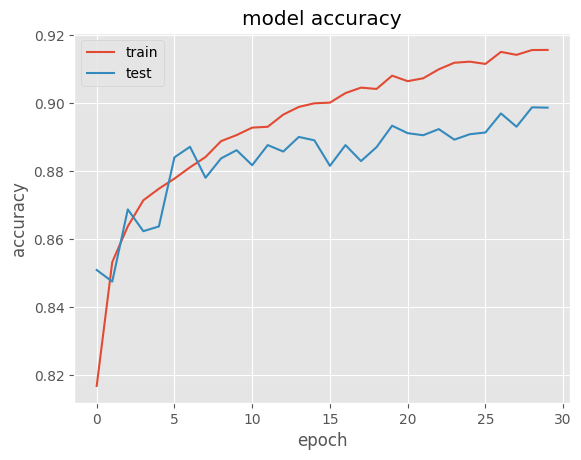

In [39]:
# summarize history for accuracy
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='best')
plt.show()

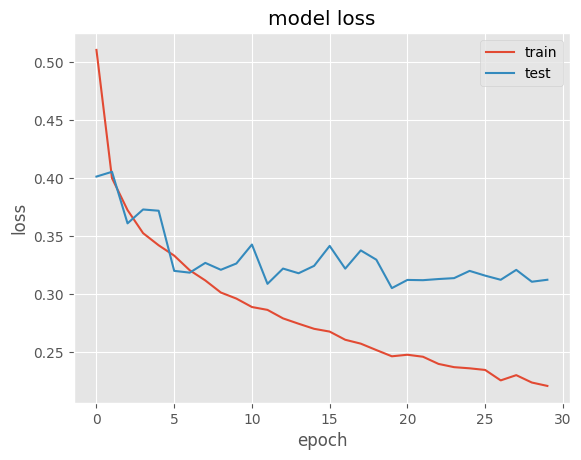

In [40]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='best')
plt.show()

In [42]:
#tf.expand_dims(X_test_digit[0])
y_predict = model.predict(x_test.loc[[0],:].values)
y_predict=np.argmax(y_predict, axis=1) # Here we get the index of maximum value in the encoded vector
y_test_digit_eval=np.argmax(y_test_fashion, axis=1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step


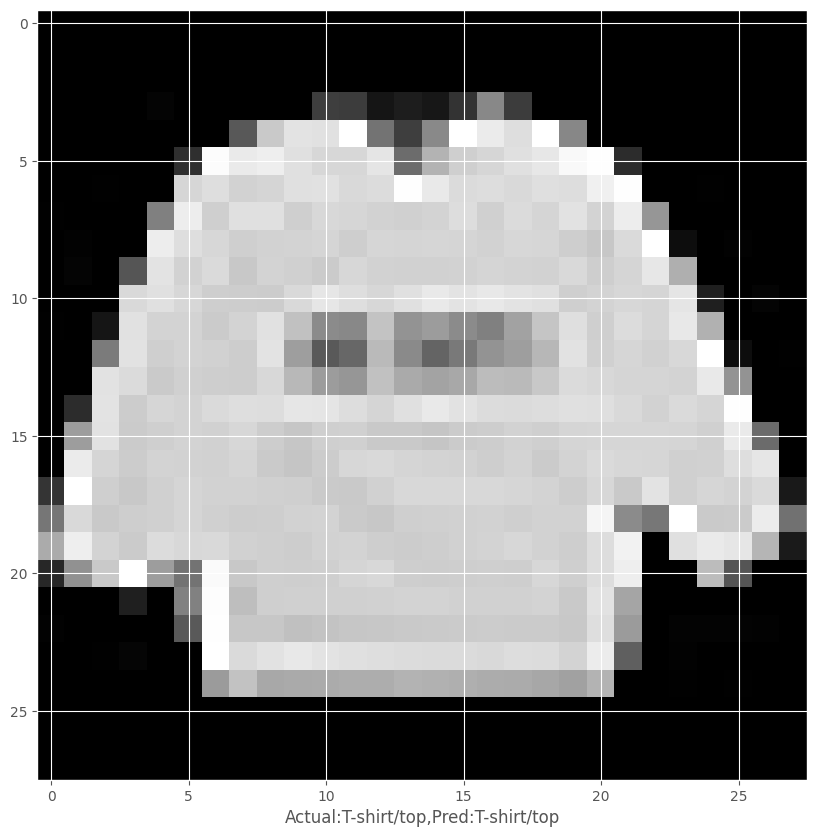

In [43]:
#Names of clothing accessories in order
col_names = ['T-shirt/top','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Ankle boot']

#Visualizing the images
plt.figure(figsize=(10,10))

plt.imshow(x_train_reshape[0], cmap='gray')
plt.xlabel("Actual:{},Pred:{}".format(col_names[np.argmax(y_test_fashion[0])],col_names[y_predict[0]]))
plt.show()